In [146]:
#Data checking and cleaning
df.head()
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5620544 entries, 0 to 5620543
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             str    
 1   rideable_type       str    
 2   started_at          str    
 3   ended_at            str    
 4   start_station_name  str    
 5   start_station_id    str    
 6   end_station_name    str    
 7   end_station_id      str    
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       str    
dtypes: float64(4), str(9)
memory usage: 557.5 MB


In [147]:
#Changing 'started_at' and ''ended_at' datatypes to datetime
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

df['start_time'] = df['started_at'].dt.time
df['end_time'] = df['ended_at'].dt.time
#Checking
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5620544 entries, 0 to 5620543
Data columns (total 15 columns):
 #   Column              Dtype         
---  ------              -----         
 0   ride_id             str           
 1   rideable_type       str           
 2   started_at          datetime64[us]
 3   ended_at            datetime64[us]
 4   start_station_name  str           
 5   start_station_id    str           
 6   end_station_name    str           
 7   end_station_id      str           
 8   start_lat           float64       
 9   start_lng           float64       
 10  end_lat             float64       
 11  end_lng             float64       
 12  member_casual       str           
 13  start_time          object        
 14  end_time            object        
dtypes: datetime64[us](2), float64(4), object(2), str(7)
memory usage: 643.2+ MB


In [148]:
#Creating new columns for day of the week and ride length
df['day_of_week'] = df['started_at'].dt.day_name()
df['ride_length'] = df['ended_at'] - df['started_at']
df['ride_length'] = df['ride_length'].dt.total_seconds()/60
df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,start_time,end_time,day_of_week,ride_length
0,FD0EB1D32AF0D47E,classic_bike,2026-01-31 09:13:09.018,2026-01-31 09:28:10.302,Central St & Girard Ave,CHI02042,Dodge Ave & Church St,CHI00741,42.064313,-87.686152,42.048308,-87.698224,member,09:13:09.018000,09:28:10.302000,Saturday,15.021400
1,FB27405C3F8C824F,classic_bike,2026-01-15 14:25:42.526,2026-01-15 14:33:18.854,Shore Dr & 55th St,CHI00394,Woodlawn Ave & 55th St,CHI00423,41.795212,-87.580715,41.795264,-87.596471,casual,14:25:42.526000,14:33:18.854000,Thursday,7.605467
2,6FAFA1709403AA27,electric_bike,2026-01-06 12:55:33.572,2026-01-06 13:02:17.922,Hampden Ct & Diversey Pkwy,CHI02087,NaN,NaN,41.932470,-87.642420,41.940000,-87.640000,member,12:55:33.572000,13:02:17.922000,Tuesday,6.739167
3,1F34C1FAD9FEC2D8,electric_bike,2026-01-26 16:22:25.011,2026-01-26 16:53:15.197,Carpenter St & Huron St,CHI00286,NaN,NaN,41.894532,-87.653412,41.830000,-87.670000,member,16:22:25.011000,16:53:15.197000,Monday,30.836433
4,8E3E3072D8D3D918,electric_bike,2026-01-10 18:13:30.139,2026-01-10 19:31:56.971,Clinton St & Madison St,CHI00233,NaN,NaN,41.881660,-87.641150,41.890000,-87.630000,member,18:13:30.139000,19:31:56.971000,Saturday,78.447200


In [149]:
#Analysis between casual riders and members

#Average ride length
df.groupby('member_casual')['ride_length'].mean()

member_casual
casual    22.593074
member    12.432349
Name: ride_length, dtype: float64

In [150]:
#Weekdays versus weekends, casual riders vs members
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories=day_order, ordered=True)
grouped = df.groupby(['day_of_week', 'member_casual'])['ride_length'].mean().reset_index()
grouped

,day_of_week,member_casual,ride_length
0,Monday,casual,22.666812
1,Monday,member,12.104747
2,Tuesday,casual,19.585884
3,Tuesday,member,11.967103
4,Wednesday,casual,18.912403
5,Wednesday,member,11.920222
6,Thursday,casual,19.837758
7,Thursday,member,11.963372
8,Friday,casual,22.344720
9,Friday,member,12.365128


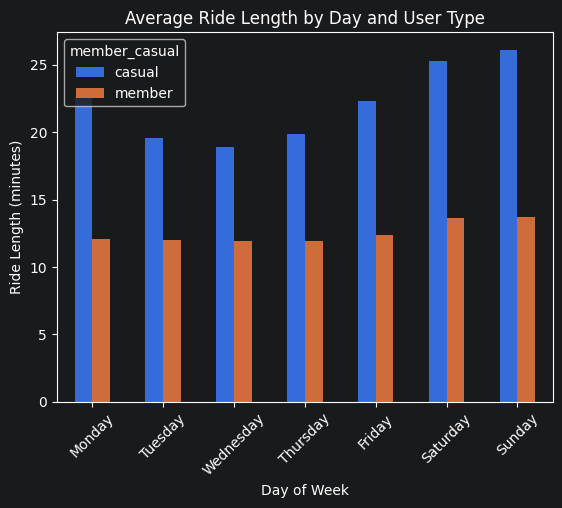

In [151]:
#Bar chart of weekdays vs weekends, casual riders vs members
import matplotlib.pyplot as plt

plot_df = grouped.pivot(index='day_of_week', columns='member_casual', values='ride_length')

ax = plot_df.plot(kind='bar', stacked=False)

plt.title('Average Ride Length by Day and User Type')
plt.xlabel('Day of Week')
plt.ylabel('Ride Length (minutes)')
plt.xticks(rotation=45)

plt.show()

In [152]:
#Confirming the average ride length difference between casual riders vs members
df.groupby('member_casual')['ride_length'].mean()

member_casual
casual    22.593074
member    12.432349
Name: ride_length, dtype: float64

In [153]:
#Number of trips taken on weekdays vs weekends
df['day_type'] = df['day_of_week'].apply(lambda x: 'Weekday' if x in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'] else 'Weekend') #Creating a new column for weekday and weekend

df['day_type'].value_counts() #Number of trips taken on weekdays are higher than on weekends, though ride lengths on weekdays are shorter (ref to bar chart above)

day_type
Weekday    4026976
Weekend    1593568
Name: count, dtype: int64

In [154]:
#Average rides taken per day
weekday_total = df[df['day_type'] == 'Weekday'].shape[0]
weekend_total = df[df['day_type'] == 'Weekend'].shape[0]

weekday_avg = weekday_total / 5
weekend_avg = weekend_total / 5

weekday_avg, weekend_avg

(805395.2, 318713.6)

In [158]:
#Average rides taken per day, grouped by member type
member_types_rides = df.groupby(['day_type', 'member_casual'])['ride_id'].count()
member_types_rides

day_type  member_casual
Weekday   casual           1261185
          member           2765791
Weekend   casual            754314
          member            839254
Name: ride_id, dtype: int64

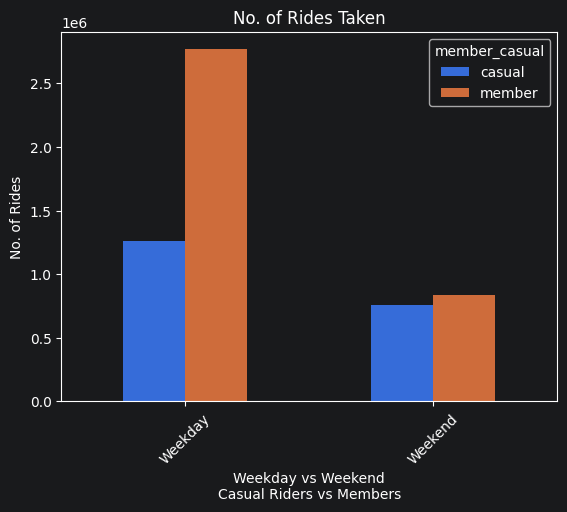

In [169]:
#Plotting bar chart
import matplotlib.pyplot as plt

counts = df.groupby(['day_type', 'member_casual']).size().reset_index(name='ride_count')
plot_df = counts.pivot(index='day_type', columns='member_casual', values='ride_count')
plot_df.plot(kind='bar', stacked=False)
plt.title('No. of Rides Taken')
plt.xlabel('Weekday vs Weekend\nCasual Riders vs Members')
plt.ylabel('No. of Rides')
plt.xticks(rotation=45)
plt.show()

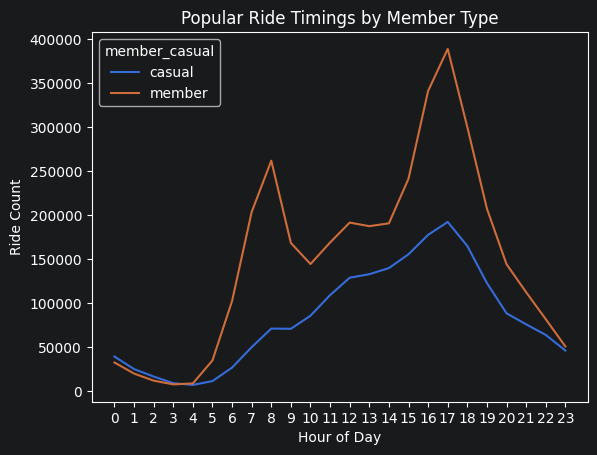

In [186]:
#Comparing peak timings between casual riders and members
df['hour'] = df['started_at'].dt.hour
#Counting no. of rides taken by hour and member type
grouped_hours = df.groupby(['hour', 'member_casual']).size().reset_index(name='ride_count')

#Plotting
import matplotlib.pyplot as plt
plot_df = grouped_hours.pivot(index='hour', columns='member_casual', values='ride_count')
plot_df.plot(kind='line')
plt.title('Popular Ride Timings by Member Type')
plt.xlabel('Hour of Day')
plt.ylabel('Ride Count')
plt.xticks(range(0,24))
plt.show()